# CP³ domain wall: bidirectional Hund-coupling scan

The normalized order parameter is a four-component spinor in the basis
$(|\uparrow,K\rangle,|\uparrow,K'\rangle,|\downarrow,K\rangle,|\downarrow,K'\rangle)$, with fixed boundary states $|\downarrow,K'\rangle$ on the left and $|\uparrow,K\rangle$ on the right.

The one-dimensional free-energy density is
$$
\mathcal H=\frac{\rho}{2}\operatorname{Tr}(\partial_xP\,\partial_xP)
-\frac{\kappa}{2}\tau_z^2
-\frac{\lambda_{\rm soc}}{2}\langle s_z\tau_z\rangle
-u_\perp\,\mathbf S_K\!\cdot\!\mathbf S_{K'},
\qquad P=|\psi\rangle\langle\psi|.
$$

The calculation scans $u_\perp/\lambda_{\rm soc}$ from 0 to 3 in both directions. Within each scan, the converged state at one coupling seeds the next. At every coupling, only the lower-energy result is retained. The final six-panel figure shows the two-component wall at zero coupling, the four-component wall at $u_\perp/\lambda_{\rm soc}=2.1$, the composite spin-valley observables, projector normalization, and the wall-center transverse order.

In [ ]:
# Imports and numerical parameters
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)
device = torch.device("cpu")
cdtype = torch.complex128

plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 15,
    "figure.dpi": 200,
})
# CP3 parameters used in the continuum calculation.
rho = 0.05
kappa = 0.24
lambda_soc = 0.1

# Real-space grid in units of the continuum length l_e.
L = 60.0
Nx = 601
x = torch.linspace(-L / 2, L / 2, Nx, device=device)
xx = x.cpu().numpy()
dx = float(x[1] - x[0])

# Minimization and scan controls. A spacing of 0.3 includes 2.1 exactly.
seed = 7
noise_amplitude = 0.02
learning_rate = 2.0e-2
tol = 1.0e-8
max_iter = 50_000
u_perp_over_lambda = np.linspace(0.0, 3.0, 11)
u_perp_values = lambda_soc * u_perp_over_lambda

print(f"Nx={Nx}, dx={dx:.4f}, scan points={len(u_perp_values)}")

Nx=601, dx=0.1000, scan points=11


In [75]:
# Spin, valley, and composite spin-valley operators
I2 = torch.eye(2, dtype=cdtype, device=device)
px = torch.tensor([[0, 1], [1, 0]], dtype=cdtype, device=device)
py = torch.tensor([[0, -1j], [1j, 0]], dtype=cdtype, device=device)
pz = torch.tensor([[1, 0], [0, -1]], dtype=cdtype, device=device)
I4 = torch.eye(4, dtype=cdtype, device=device)

spin_operators = torch.stack([torch.kron(p, I2) for p in (px, py, pz)])
valley_operators = torch.stack([torch.kron(I2, p) for p in (px, py, pz)])
correlation_operators = torch.stack([
    spin @ valley for spin in spin_operators for valley in valley_operators
])
sztz_operator = spin_operators[2] @ valley_operators[2]

P_K = (I4 + valley_operators[2]) / 2
P_Kp = (I4 - valley_operators[2]) / 2
SK_operators = torch.stack([spin @ P_K for spin in spin_operators])
SKp_operators = torch.stack([spin @ P_Kp for spin in spin_operators])

left_boundary = torch.tensor([0, 0, 0, 1], dtype=cdtype, device=device)
right_boundary = torch.tensor([1, 0, 0, 0], dtype=cdtype, device=device)

def expectations(state, operators):
    """Return local expectation values for a collection of operators."""
    return torch.einsum("ni,kij,nj->nk", state.conj(), operators, state).real

def observables(state):
    """Return the observables retained for the final figure."""
    return {
        "spin": expectations(state, spin_operators),
        "valley": expectations(state, valley_operators),
        "correlation": expectations(state, correlation_operators).reshape(Nx, 3, 3),
        "projector_trace": torch.sum(torch.abs(state) ** 2, dim=1),
    }
spin_z_eigenvalues = torch.tensor(
    [1, 1, -1, -1], dtype=torch.float64, device=device
)
valley_z_eigenvalues = torch.tensor(
    [1, -1, 1, -1], dtype=torch.float64, device=device
)


def orient_transverse_positive(state, tolerance=1e-10):
    """Choose the symmetry-equivalent state with positive s_x and tau_x."""

    state = state.detach().clone()
    obs = observables(state)

    sx_profile = obs["spin"][:, 0]
    tx_profile = obs["valley"][:, 0]

    sx_index = int(torch.argmax(torch.abs(sx_profile)))
    tx_index = int(torch.argmax(torch.abs(tx_profile)))

    spin_angle = 0.0
    valley_angle = 0.0

    if torch.abs(sx_profile[sx_index]).item() > tolerance:
        if sx_profile[sx_index].item() < 0:
            spin_angle = np.pi

    if torch.abs(tx_profile[tx_index]).item() > tolerance:
        if tx_profile[tx_index].item() < 0:
            valley_angle = np.pi

    phase = torch.exp(
        -0.5j * (
            spin_angle * spin_z_eigenvalues
            + valley_angle * valley_z_eigenvalues
        )
    ).to(cdtype)

    state *= phase[None, :]

    # Restore the exact stored boundary-vector convention.
    state[0] = left_boundary
    state[-1] = right_boundary

    return state

def make_initial_wall(seed_value):
    """Smooth wall with small real noise to seed competing CP³ minima."""
    angle = torch.linspace(0, np.pi / 2, Nx, device=device)
    state = (torch.cos(angle)[:, None] * left_boundary
             + torch.sin(angle)[:, None] * right_boundary)
    generator = torch.Generator(device=device).manual_seed(seed_value)
    noise = torch.randn((Nx - 2, 4), generator=generator, device=device)
    state[1:-1] += noise_amplitude * noise
    state /= torch.linalg.vector_norm(state, dim=1, keepdim=True)
    state[0] = left_boundary
    state[-1] = right_boundary
    return state

In [ ]:
# Free energy and normalized gradient descent
def energy_density(state, u_perp):
    """Return the local terms in the discretized CP³ free energy."""
    projector = torch.einsum("ni,nj->nij", state, state.conj())
    d_projector = (projector[1:] - projector[:-1]) / dx
    gradient_links = rho * torch.sum(torch.abs(d_projector) ** 2, dim=(1, 2)) / 2

    # Split each link contribution equally between its neighboring sites.
    gradient = torch.zeros(Nx, device=device)
    gradient[:-1] += 0.5 * gradient_links
    gradient[1:] += 0.5 * gradient_links

    spin = expectations(state, spin_operators)
    valley = expectations(state, valley_operators)
    sztz = torch.einsum("ni,ij,nj->n", state.conj(), sztz_operator, state).real
    spin_K = expectations(state, SK_operators)
    spin_Kp = expectations(state, SKp_operators)
    terms = {
        "gradient": gradient,
        "valley": -0.5 * kappa * valley[:, 2] ** 2,
        "soc": -0.5 * lambda_soc * sztz,
        "hund": -u_perp * torch.sum(spin_K * spin_Kp, dim=1),
    }
    terms["total"] = sum(terms.values())
    return terms

def total_energy(state, u_perp):
    return dx * energy_density(state, u_perp)["total"].sum()

def minimize_wall(state_start, u_perp):
    """Minimize at fixed coupling while preserving normalization and boundaries."""
    state = state_start.detach().clone()
    energy_history = [total_energy(state, u_perp).item()]
    step_size = learning_rate
    monotonic_slack = 1.0e-12

    for iteration in range(1, max_iter + 1):
        variable = state.detach().clone().requires_grad_(True)
        old_energy_tensor = total_energy(variable, u_perp)
        old_energy_tensor.backward()
        gradient = variable.grad.detach()
        old_energy = old_energy_tensor.item()

        trial_step = step_size
        accepted = False
        for _ in range(30):
            with torch.no_grad():
                trial = variable.detach().clone()
                trial[1:-1] -= trial_step * gradient[1:-1]
                trial[1:-1] /= torch.linalg.vector_norm(
                    trial[1:-1], dim=1, keepdim=True
                )
                trial[0] = left_boundary
                trial[-1] = right_boundary
                new_energy = total_energy(trial, u_perp).item()
            if new_energy <= old_energy + monotonic_slack:
                accepted = True
                break
            trial_step *= 0.5

        if not accepted:
            break

        state = trial
        step_size = trial_step
        energy_history.append(new_energy)
        if abs(new_energy - old_energy) < tol:
            break

    energy_history = np.asarray(energy_history)
    converged = (len(energy_history) > 1
                 and abs(energy_history[-1] - energy_history[-2]) < tol)
    return state, energy_history, iteration, converged

In [77]:
# Wall geometry and continuation helpers
def wall_geometry(position, longitudinal_profile):
    """Locate the center and the two ±tanh(1) crossings of a wall."""
    profile = np.asarray(longitudinal_profile)
    offset = 0.5 * (profile[-1] + profile[0])
    amplitude = 0.5 * (profile[-1] - profile[0])
    normalized = (profile - offset) / amplitude
    # Interpolate the crossings instead of rounding them to grid points.
    # The optimized longitudinal profiles are monotonic for the walls used here.
    target = np.tanh(1.0)
    edges = np.interp([-target, target], normalized, position)
    center = float(np.interp(0.0, normalized, position))
    width = edges[1] - edges[0]
    return edges, center, width

def make_record(state, u_perp, energy, iterations, converged, scan):
    obs = observables(state)
    return {
        "u_perp": float(u_perp),
        "energy": float(energy),
        "iterations": int(iterations),
        "converged": bool(converged),
        "scan": scan,
        "spin": obs["spin"].detach().cpu().numpy(),
        "valley": obs["valley"].detach().cpu().numpy(),
        "correlation": obs["correlation"].detach().cpu().numpy(),
        "projector_trace": obs["projector_trace"].detach().cpu().numpy(),
    }

def continuation_scan(couplings, initial_state, scan):
    """Use each converged state to seed the next coupling in one scan direction."""
    records = []
    state = initial_state
    for coupling in couplings:
        state, history, iterations, converged = minimize_wall(state, float(coupling))
        state=orient_transverse_positive(state)
        records.append(make_record(
            state, coupling, history[-1], iterations, converged, scan
        ))
        print(
            f"{scan:10s} u_perp/lambda={coupling / lambda_soc:4.1f}  "
            f"E={history[-1]: .10f}  iterations={iterations:5d}  "
            f"converged={converged}"
        )
    return records

## Bidirectional continuation

The ascending scan starts at zero coupling; the descending scan starts independently at the largest coupling. Results from the descending scan are reversed into ascending-coupling order before comparing the two energies.

In [78]:
ascending_results = continuation_scan(
    u_perp_values, make_initial_wall(seed), scan="ascending"
)
descending_results = list(reversed(continuation_scan(
    u_perp_values[::-1], make_initial_wall(seed + 1), scan="descending"
)))

# Retain only the lower-energy state at each coupling.
selected_results = []
print("\nSelected lower-energy results")
print("u_perp/lambda      E_ascending       E_descending       selected")
for ratio, ascending, descending in zip(
    u_perp_over_lambda, ascending_results, descending_results
):
    selected = ascending if ascending["energy"] <= descending["energy"] else descending
    selected_results.append(selected)
    print(
        f"{ratio:8.3f}       {ascending['energy']: .10f}   "
        f"{descending['energy']: .10f}     {selected['scan']}"
    )

if not all(result["converged"] for result in selected_results):
    print("Warning: at least one selected state did not meet the tolerance.")

ascending  u_perp/lambda= 0.0  E=-10.0627067653  iterations= 4733  converged=True
ascending  u_perp/lambda= 0.3  E=-10.0580000268  iterations=  832  converged=True
ascending  u_perp/lambda= 0.6  E=-10.0534332185  iterations=  786  converged=True
ascending  u_perp/lambda= 0.9  E=-10.0489950834  iterations=  738  converged=True
ascending  u_perp/lambda= 1.2  E=-10.0446757487  iterations=  696  converged=True
ascending  u_perp/lambda= 1.5  E=-10.0404665250  iterations=  659  converged=True
ascending  u_perp/lambda= 1.8  E=-10.0363597224  iterations=  625  converged=True
ascending  u_perp/lambda= 2.1  E=-10.0323485353  iterations=  595  converged=True
ascending  u_perp/lambda= 2.4  E=-10.0284268631  iterations=  567  converged=True
ascending  u_perp/lambda= 2.7  E=-10.0245892572  iterations=  542  converged=True
ascending  u_perp/lambda= 3.0  E=-10.0208307950  iterations=  519  converged=True
descending u_perp/lambda= 3.0  E=-10.0472704162  iterations=11969  converged=True
descending u_per

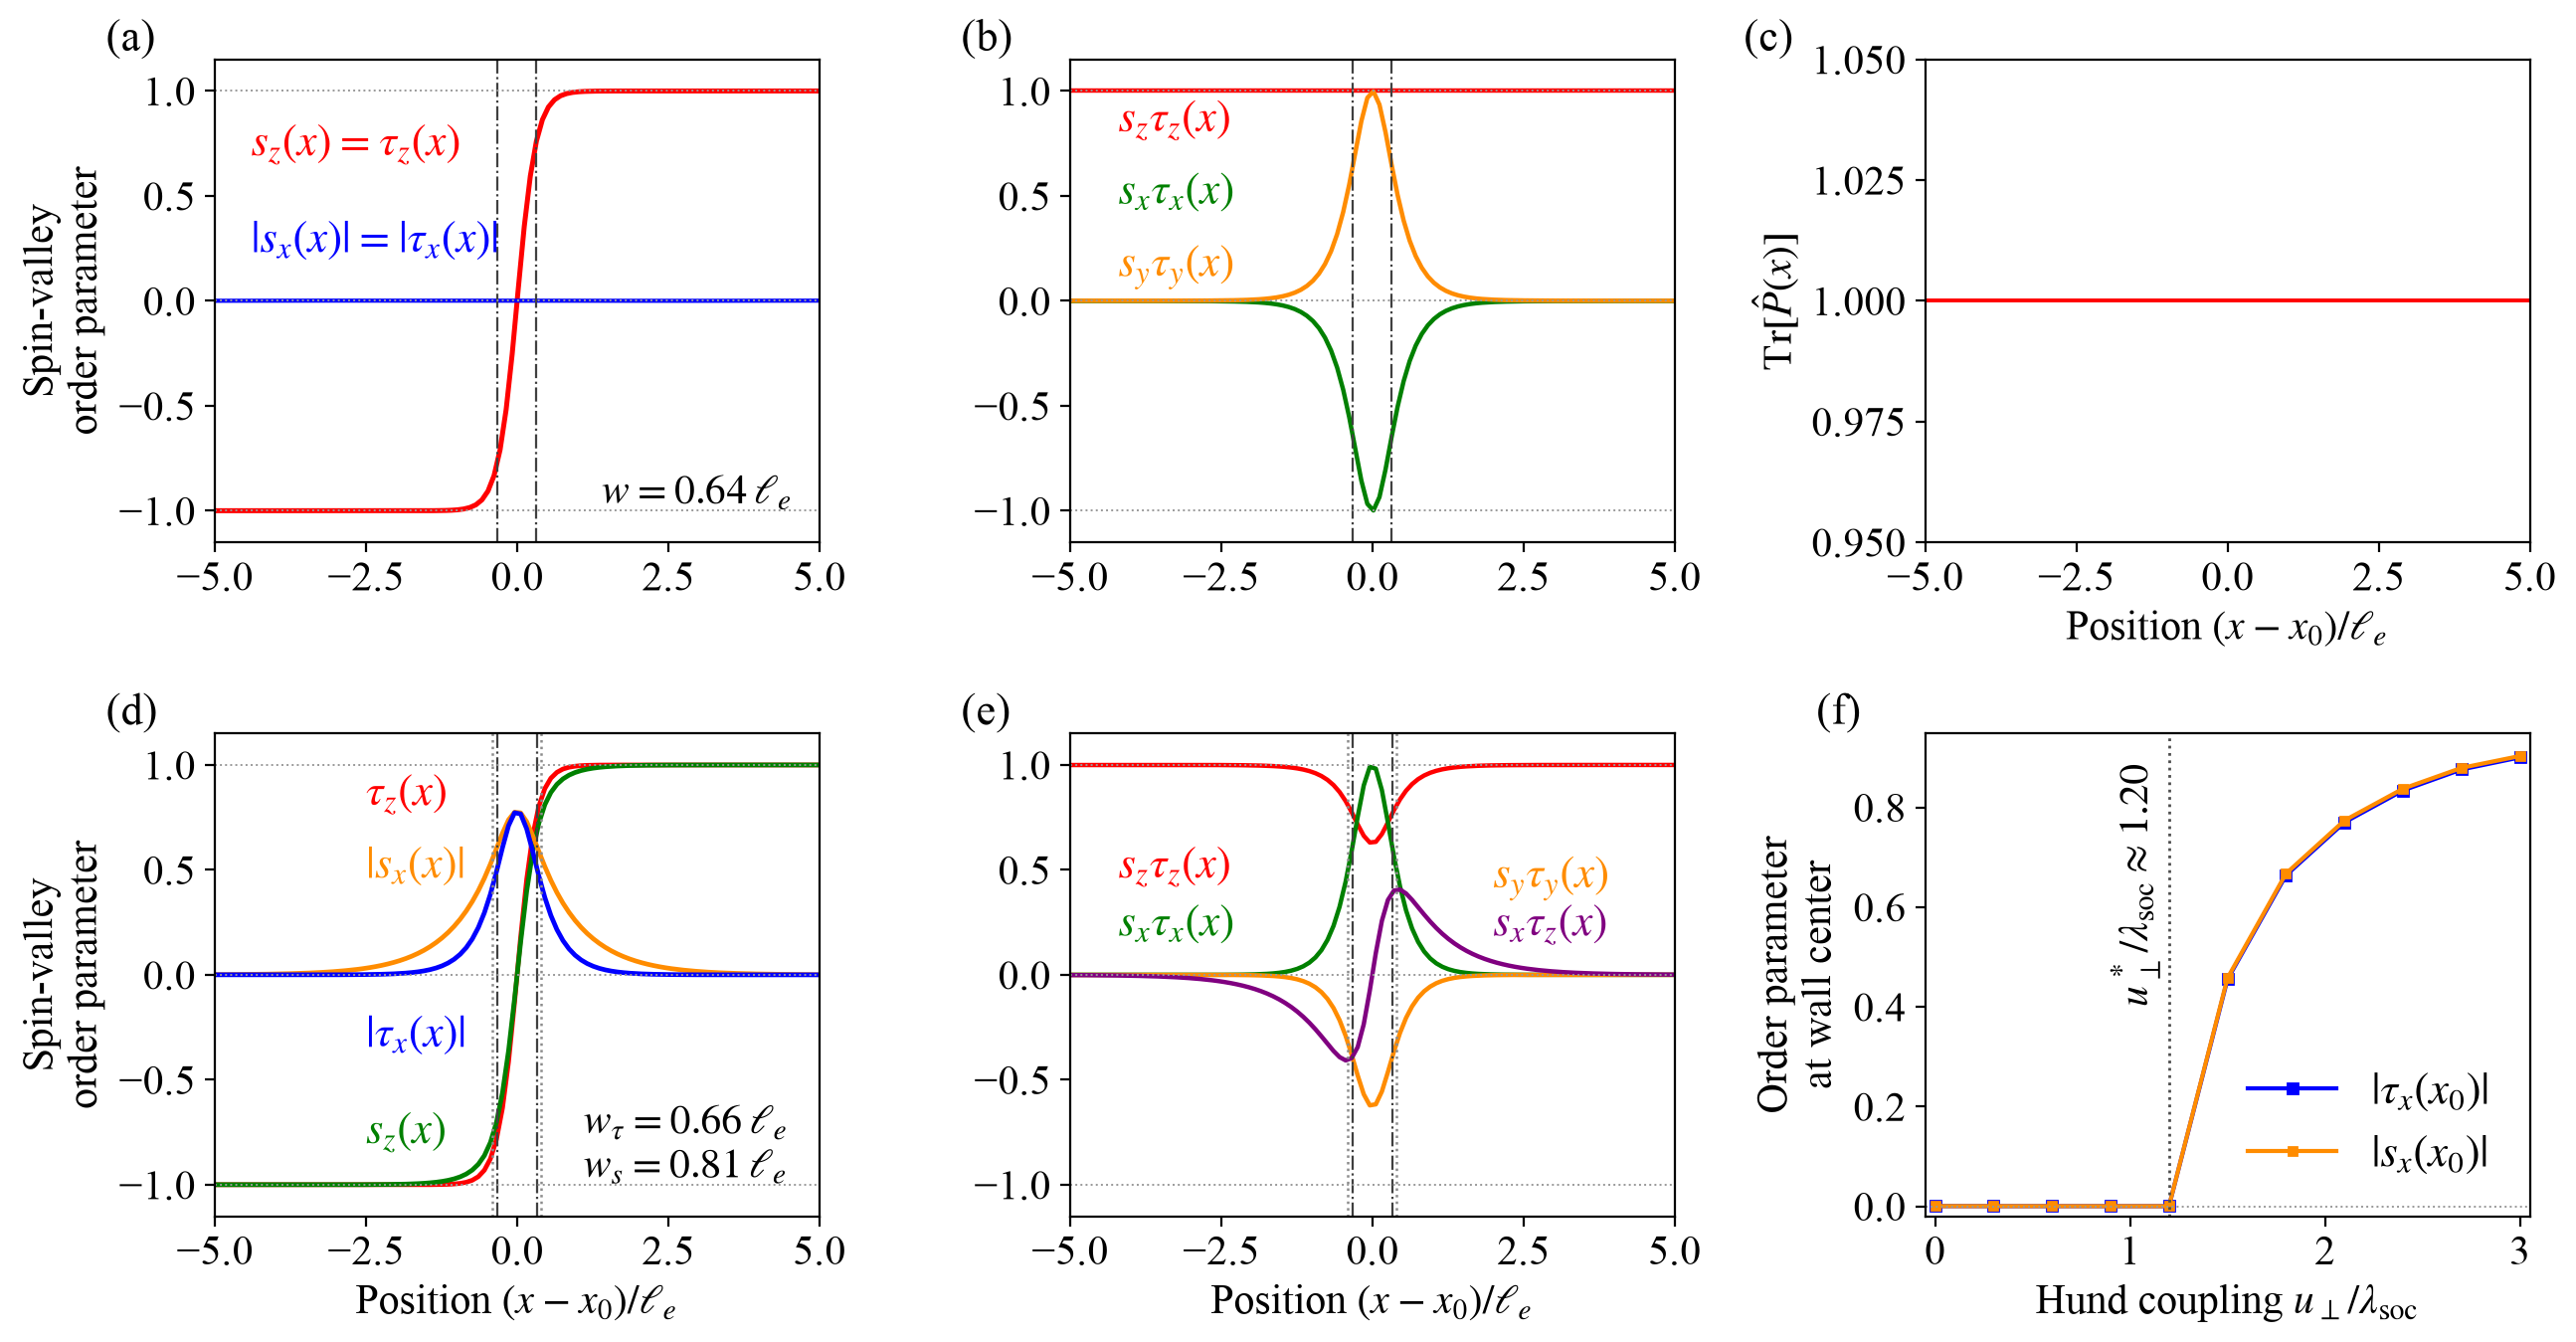

Estimated u_perp*/lambda_soc = 1.200


In [90]:
# Six-panel summary (Supplementary Figure 6)
zero_result = selected_results[0]
target_index = int(np.argmin(np.abs(u_perp_over_lambda - 2.1)))
if not np.isclose(u_perp_over_lambda[target_index], 2.1):
    raise ValueError("The coupling grid must contain u_perp/lambda_soc = 2.1.")
four_component_result = selected_results[target_index]

def centered_data(result):
    spin = result["spin"]
    valley = result["valley"]
    spin_edges, spin_center, spin_width = wall_geometry(xx, spin[:, 2])
    valley_edges, valley_center, valley_width = wall_geometry(xx, valley[:, 2])
    x0 = 0.5 * (spin_center + valley_center)
    return {
        "x": xx - x0,
        "x0": x0,
        "spin_edges": spin_edges - x0,
        "valley_edges": valley_edges - x0,
        "spin_width": spin_width,
        "valley_width": valley_width,
    }

zero_geometry = centered_data(zero_result)
four_geometry = centered_data(four_component_result)

# Center-order magnitudes for panel (f).
center_sx, center_tx = [], []
for result in selected_results:
    geometry = centered_data(result)
    center_sx.append(abs(np.interp(geometry["x0"], xx, result["spin"][:, 0])))
    center_tx.append(abs(np.interp(geometry["x0"], xx, result["valley"][:, 0])))
center_sx = np.asarray(center_sx)
center_tx = np.asarray(center_tx)

# Estimate the transition from the first crossing of the two continuation energies.
energy_difference = np.asarray([
    ascending["energy"] - descending["energy"]
    for ascending, descending in zip(ascending_results, descending_results)
])
nonzero_threshold = 1.0e-3
both_nonzero = (
    (center_sx > nonzero_threshold)
    & (center_tx > nonzero_threshold)
)

first_nonzero = np.flatnonzero(both_nonzero)

critical_ratio = None
if first_nonzero.size:
    critical_index = max(int(first_nonzero[0]) - 1, 0)
    critical_ratio = float(u_perp_over_lambda[critical_index])
# crossings = np.flatnonzero(energy_difference[:-1] * energy_difference[1:] < 0)
# critical_ratio = None
# if crossings.size:
#     left = int(crossings[0])
#     d0, d1 = energy_difference[left:left + 2]
#     r0, r1 = u_perp_over_lambda[left:left + 2]
#     critical_ratio = r0 - d0 * (r1 - r0) / (d1 - d0)

red = "#ff0000"
blue = "#0000ff"
green = "#008000"
orange = "#ff8c00"
purple = "#800080"

fig, axes = plt.subplots(2, 3, figsize=(13.2, 7.0))

def decorate_profile_axis(axis, panel, show_xlabel=False):
    axis.set_xlim(-5, 5)
    axis.set_ylim(-1.15, 1.15)
    axis.axhline(0, color="0.6", ls=":", lw=0.7)
    axis.axhline(1, color="0.6", ls=":", lw=0.7)
    axis.axhline(-1, color="0.6", ls=":", lw=0.7)
    axis.text(-0.18, 1.02, f"({panel})", transform=axis.transAxes, fontsize=16)
    if show_xlabel:
        axis.set_xlabel(r"Position $(x-x_0)/\ell_e$")

def add_wall_edges(axis, geometry, both=True):
    for edge in geometry["valley_edges"]:
        axis.axvline(edge, color="0.25", ls="-.", lw=0.8)
    if both:
        for edge in geometry["spin_edges"]:
            axis.axvline(edge, color="0.55", ls=":", lw=0.9)

# (a) Two-component spin and valley profiles at u_perp = 0.
axis = axes[0, 0]
spin, valley = zero_result["spin"], zero_result["valley"]
axis.plot(zero_geometry["x"], spin[:, 2], color=red, lw=1.8,
          label=r"$s_z(x)=\tau_z(x)$")
axis.plot(zero_geometry["x"], np.abs(spin[:, 0]), color=blue, lw=1.5,
          label=r"$|s_x(x)|=|\tau_x(x)|$")
add_wall_edges(axis, zero_geometry, both=False)
axis.text(0.64, 0.08, rf"$w={zero_geometry['spin_width']:.2f}\,\ell_e$",
          transform=axis.transAxes)
axis.set_ylabel("Spin-valley\norder parameter")
axis.text(0.06, 0.8, r"$s_z(x)=\tau_z(x)$",
          color=red, transform=axis.transAxes, fontsize=16)
axis.text(0.06, 0.6, r"$|s_x(x)|=|\tau_x(x)|$",
          color=blue, transform=axis.transAxes, fontsize=16)
decorate_profile_axis(axis, "a")
# (b) Composite order parameters for the two-component wall.
axis = axes[0, 1]
corr = zero_result["correlation"]
axis.plot(zero_geometry["x"], corr[:, 2, 2], color=red, lw=1.6,
          label=r"$s_z\tau_z$")
axis.plot(zero_geometry["x"], corr[:, 0, 0], color=green, lw=1.6,
          label=r"$s_x\tau_x(x)$")
axis.plot(zero_geometry["x"], corr[:, 1, 1], color=orange, lw=1.6,
          label=r"$s_y\tau_y(x)$")
add_wall_edges(axis, zero_geometry, both=False)
axis.text(0.08, 0.85, r"$s_z\tau_z(x)$",
          color=red, transform=axis.transAxes, fontsize=16)
axis.text(0.08, 0.7, r"$s_x\tau_x(x)$",
          color=green, transform=axis.transAxes, fontsize=16)
axis.text(0.08, 0.55, r"$s_y\tau_y(x)$",
          color=orange, transform=axis.transAxes, fontsize=16)
decorate_profile_axis(axis, "b")

# (c) CP³ projector normalization.
axis = axes[0, 2]
axis.plot(zero_geometry["x"], zero_result["projector_trace"], color=red, lw=1.4)
axis.set_xlim(-5, 5)
axis.set_ylim(0.95, 1.05)
axis.set_xlabel(r"Position $(x-x_0)/\ell_e$")
axis.set_ylabel(r"$\mathrm{Tr}[\hat P(x)]$")
axis.text(-0.3, 1.02, "(c)", transform=axis.transAxes, fontsize=16)

# (d) Four-component profiles at u_perp/lambda_soc = 2.1.
axis = axes[1, 0]
spin, valley = four_component_result["spin"], four_component_result["valley"]
axis.plot(four_geometry["x"], valley[:, 2], color=red, lw=1.7, label=r"$\tau_z$")
axis.plot(four_geometry["x"], spin[:, 2], color=green, lw=1.7, label=r"$s_z$")
axis.plot(four_geometry["x"], np.abs(spin[:, 0]), color=orange, lw=1.7,
          label=r"$|s_x|$")
axis.plot(four_geometry["x"], np.abs(valley[:, 0]), color=blue, lw=1.7,
          label=r"$|\tau_x|$")
add_wall_edges(axis, four_geometry, both=True)
axis.text(
    0.61, 0.08,
    rf"$w_\tau={four_geometry['valley_width']:.2f}\,\ell_e$" + "\n"
    + rf"$w_s={four_geometry['spin_width']:.2f}\,\ell_e$",
    transform=axis.transAxes,
)
axis.set_ylabel("Spin-valley\norder parameter")
axis.text(0.25, 0.85, r"$\tau_z(x)$",
          color=red, transform=axis.transAxes, fontsize=16)
axis.text(0.25, 0.15, r"$s_z(x)$",
          color=green, transform=axis.transAxes, fontsize=16)
axis.text(0.25, 0.7, r"$|s_x(x)|$",
          color=orange, transform=axis.transAxes, fontsize=16)
axis.text(0.25, 0.35, r"$|\tau_x(x)|$",
          color=blue, transform=axis.transAxes, fontsize=16)
decorate_profile_axis(axis, "d", show_xlabel=True)

# (e) Composite order parameters for the four-component wall.
axis = axes[1, 1]
corr = four_component_result["correlation"]
axis.plot(four_geometry["x"], corr[:, 2, 2], color=red, lw=1.6,
          label=r"$s_z\tau_z(x)$")
axis.plot(four_geometry["x"], corr[:, 0, 0], color=green, lw=1.6,
          label=r"$s_x\tau_x(x)$")
axis.plot(four_geometry["x"], corr[:, 1, 1], color=orange, lw=1.6,
          label=r"$s_y\tau_y(x)$")
axis.plot(four_geometry["x"], corr[:, 0, 2], color=purple, lw=1.6,
          label=r"$s_x\tau_z(x)$")
add_wall_edges(axis, four_geometry, both=True)
axis.text(0.08, 0.7, r"$s_z\tau_z(x)$",
          color=red, transform=axis.transAxes, fontsize=16)
axis.text(0.08, 0.58, r"$s_x\tau_x(x)$",
          color=green, transform=axis.transAxes, fontsize=16)
axis.text(0.70, 0.68, r"$s_y\tau_y(x)$",
          color=orange, transform=axis.transAxes, fontsize=16)
axis.text(0.70, 0.58, r"$s_x\tau_z(x)$",
          color=purple, transform=axis.transAxes, fontsize=16)
decorate_profile_axis(axis, "e", show_xlabel=True)

# (f) Magnitudes of the transverse order parameters at the wall center.
axis = axes[1, 2]
axis.plot(u_perp_over_lambda, center_tx, "s-", color=blue, ms=3.5,
          label=r"$|\tau_x(x_0)|$")
axis.plot(u_perp_over_lambda, center_sx, "s-", color=orange, ms=3.0,
          label=r"$|s_x(x_0)|$")
if critical_ratio is not None:
    axis.axvline(critical_ratio, color="0.3", ls=":", lw=1.0)
    axis.text(
        critical_ratio - 0.3, 0.4,
        rf"$u_\perp^*/\lambda_{{\rm soc}}\approx{critical_ratio:.2f}$",
        rotation=90, va="bottom", ha="left",
    )
axis.axhline(0, color="0.6", ls=":", lw=0.7)
axis.set_xlim(-0.05, 3.05)
axis.set_ylim(bottom=-0.02)
axis.set_xlabel(r"Hund coupling $u_\perp/\lambda_{\rm soc}$")
axis.set_ylabel("Order parameter\nat wall center")
axis.legend(frameon=False, fontsize=16)
axis.text(-0.18, 1.02, "(f)", transform=axis.transAxes, fontsize=16)

fig.tight_layout()
plt.show()

if critical_ratio is None:
    print("No branch-energy crossing was resolved on this coupling grid.")
else:
    print(f"Estimated u_perp*/lambda_soc = {critical_ratio:.3f}")